# 09 — C-NMC source inspection

**Purpose:** Discover labeled training folds, decode cells, audit counts and patient IDs.

**Required inputs:** C-NMC `C-NMC_training_data/fold_0..2/{all,hem}` beneath cnmc_root; `training_data` is also supported. Preliminary/final challenge folders are excluded.

**Saved outputs:** cnmc_manifest.csv, dataset_inspection.json, sample and class-distribution figures.

## 1. Load central configuration

Set `cnmc_root` once in ignored `config.local.yaml`. Source images are never moved or changed.

In [10]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "classifier_config.py").is_file():
        sys.path.insert(0, str(candidate)); break
from src.classifier_config import classifier_config, classifier_output
cfg = classifier_config()
out = classifier_output(cfg)
print("Project:", cfg["root"])
print("Config:", cfg["config_path"])
print("C-NMC source:", cfg["cnmc_root"])

Project: D:\CellCancer\leukemia-yolo
Config: D:\CellCancer\leukemia-yolo\config.local.yaml
C-NMC source: D:\Datasets\C-NMC_Leukemia


## 2. Verify source and metadata

The official 10,661-image count is a comparison, not an assumed local result.

In [11]:
from src.cnmc_data import inspect_cnmc
import pandas as pd
frame, report = inspect_cnmc(cfg)
print("Verified training folder:", report["training_data"])
display(pd.DataFrame([{"metric": key, "value": str(value)} for key, value in report.items() if key != "errors"]))
display(frame.groupby(["fold", "class_name"]).size().rename("cells").reset_index())
display(frame.groupby(["subject_id", "class_name"]).size().rename("cells").reset_index().head(20))
display(frame[["image_width", "image_height", "image_channels"]].describe())

Verified training folder: D:\Datasets\C-NMC_Leukemia\C-NMC_training_data


,metric,value
0,training_data,D:\Datasets\C-NMC_Leukemia\C-NMC_training_data
1,total_images,10661
2,class_counts,"{'ALL': 7272, 'HEM': 3389}"
3,expected_training_counts,"{'ALL': 7272, 'HEM': 3389, 'total': 10661, 'su..."
4,matches_official_counts,True
5,fold_class_counts,"{'fold_0/ALL': 2397, 'fold_0/HEM': 1130, 'fold..."
6,subject_count,73
7,duplicate_filenames,[]
8,duplicate_content,"['fold_0\\all\\UID_20_10_1_all.bmp', 'fold_0\\..."
9,unexpected_files,[]


,fold,class_name,cells
0,fold_0,ALL,2397
1,fold_0,HEM,1130
2,fold_1,ALL,2418
3,fold_1,HEM,1163
4,fold_2,ALL,2457
5,fold_2,HEM,1096


,subject_id,class_name,cells
0,ALL:1,ALL,19
1,ALL:11,ALL,92
2,ALL:13,ALL,89
3,ALL:14,ALL,99
4,ALL:15,ALL,58
5,ALL:16,ALL,53
6,ALL:17,ALL,74
7,ALL:18,ALL,74
8,ALL:19,ALL,9
9,ALL:2,ALL,84


,image_width,image_height,image_channels
count,10661.0,10661.0,10661.0
mean,450.0,450.0,3.0
std,0.0,0.0,0.0
min,450.0,450.0,3.0
25%,450.0,450.0,3.0
50%,450.0,450.0,3.0
75%,450.0,450.0,3.0
max,450.0,450.0,3.0


## 3. Save labeled gallery

Eight normal and eight blast examples are selected when available.

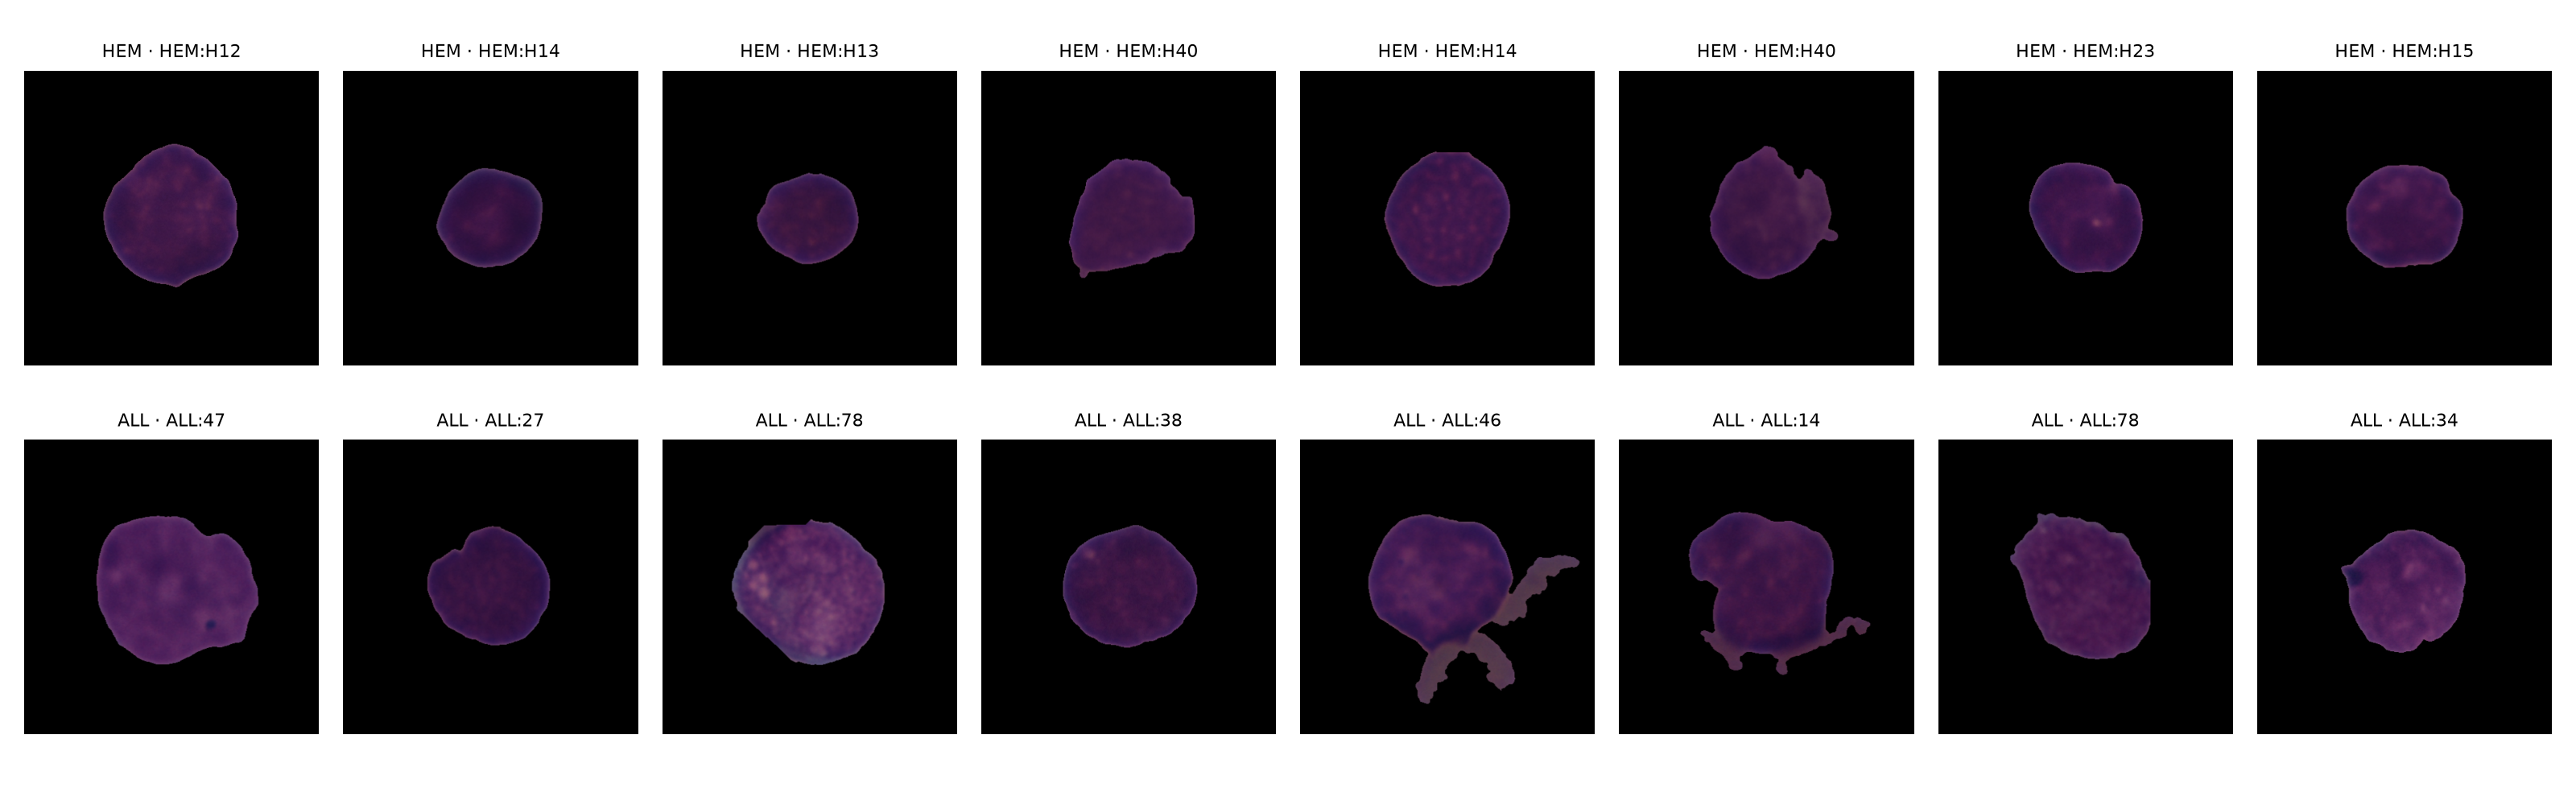

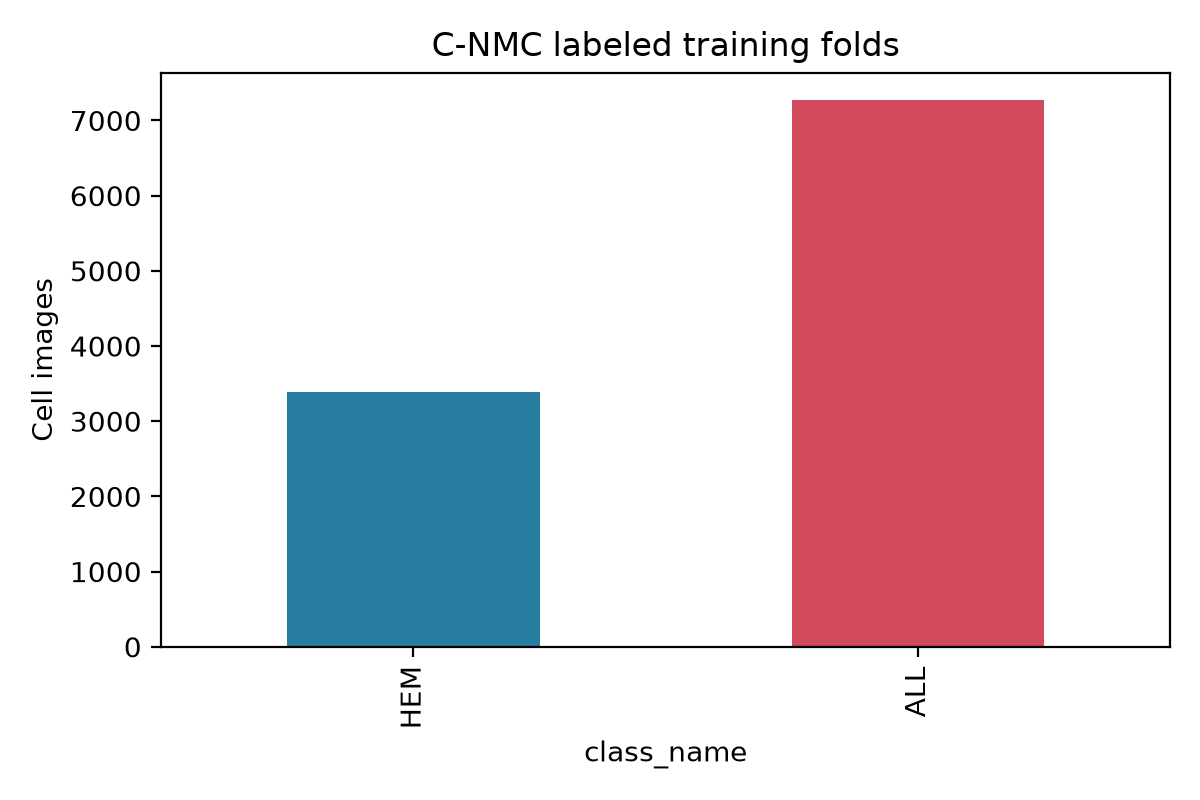

In [12]:
from src.cnmc_data import sample_figures
from IPython.display import Image as DisplayImage, display
sample_figures(frame, out / "figures")
display(DisplayImage(filename=str(out / "figures" / "cnmc_samples.png")))
display(DisplayImage(filename=str(out / "figures" / "class_distribution.png")))

## 4. Integrity summary

Invalid subject names, damaged images, or duplicate filenames block inspection. Notebook 10 audits duplicate image content, excludes test-overlapping candidate subjects, and groups duplicate-linked subjects.

In [13]:
assert report["ready"] and frame.class_id.isin([0, 1]).all()
print("PASS — source untouched; manifest saved. Official count match:", report["matches_official_counts"])

PASS — source untouched; manifest saved. Official count match: True


## Next

Open **10_CNMC_Patient_Split.ipynb**; never split images randomly.